In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

In [4]:
data = pd.read_csv("train.csv")
data['date'] = pd.to_datetime(data['date'])

df = data[(data['store']==1) & (data['item']==1)].copy()
df = df.sort_values('date')

df['lag_1'] = df['sales'].shift(1)
df['lag_7'] = df['sales'].shift(7)
df['lag_30'] = df['sales'].shift(30)

df['rolling_7'] = df['sales'].shift(1).rolling(7).mean()
df['rolling_30'] = df['sales'].shift(1).rolling(30).mean()

df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek

df = df.dropna()

features = [
    'lag_1','lag_7','lag_30',
    'rolling_7','rolling_30',
    'month','day_of_week'
]

In [5]:
window = 900       # training window
horizon = 180      # validation window
step = 180

mae_scores = []
fold = 1

for start in range(0, len(df)-window-horizon, step):

    train = df.iloc[start:start+window]
    valid = df.iloc[start+window:start+window+horizon]

    X_train = train[features]
    y_train = train['sales']

    X_valid = valid[features]
    y_valid = valid['sales']

    model = xgb.XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        random_state=42
    )

    model.fit(X_train, y_train)
    preds = model.predict(X_valid)

    mae = mean_absolute_error(y_valid, preds)
    mae_scores.append(mae)

    print(f"Fold {fold} MAE:", mae)
    fold += 1

Fold 1 MAE: 4.418816566467285
Fold 2 MAE: 3.8235113620758057
Fold 3 MAE: 4.344763278961182
Fold 4 MAE: 4.5079665184021


In [6]:
print("Average MAE:", np.mean(mae_scores))

Average MAE: 4.273764431476593


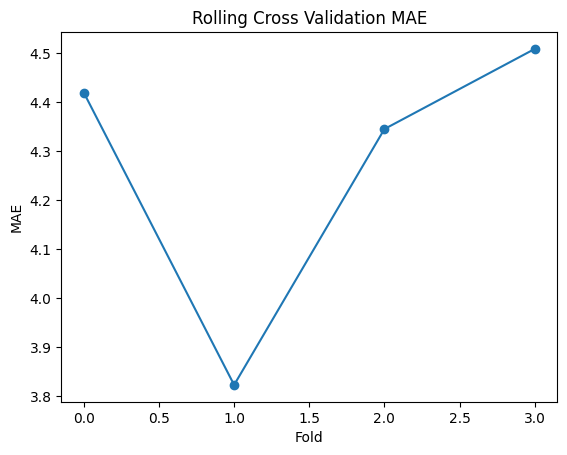

In [7]:
plt.plot(mae_scores, marker='o')
plt.title("Rolling Cross Validation MAE")
plt.xlabel("Fold")
plt.ylabel("MAE")
plt.show()